# Customer Churn – Exploratory Data Analysis (Mini Project 1)

**Objective:** an e-commerce company wants to understand which users churn, so it can design
targeted promotions to keep them. This notebook uses descriptive statistics to describe how
churned customers behave, and recommends actions to reduce churn.

**Dataset:** `customer_churn_dataset.csv`, 505,207 rows × 12 columns (customer profile,
usage, support, payment and contract information, plus the `Churn` target, 1 = churned).

**Contents**
1. Data understanding
2. Data cleaning
3. Descriptive statistics
4. Relationship analysis (each feature vs. churn)
5. Business insights & recommendations

In [1]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
# Load the data: use the local file if it is next to the notebook (VS Code),
# otherwise download it from the GitHub repo (Colab).
DATA_FILE = "customer_churn_dataset.csv"
DATA_URL = "https://raw.githubusercontent.com/Thanhnt-da/customer-churn-analysis/main/customer_churn_dataset.csv"

df_raw = pd.read_csv(DATA_FILE if os.path.exists(DATA_FILE) else DATA_URL)
df_raw.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


## 1. Data Understanding  (rubric #1)

### 1.1 Size: number of records and features

In [3]:
df_raw.shape

(505207, 12)

### 1.2 Data types

In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 505207 entries, 0 to 505206
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CustomerID         505206 non-null  float64
 1   Age                505206 non-null  float64
 2   Gender             505206 non-null  str    
 3   Tenure             505206 non-null  float64
 4   Usage Frequency    505206 non-null  float64
 5   Support Calls      505206 non-null  float64
 6   Payment Delay      505206 non-null  float64
 7   Subscription Type  505206 non-null  str    
 8   Contract Length    505206 non-null  str    
 9   Total Spend        505206 non-null  float64
 10  Last Interaction   505206 non-null  float64
 11  Churn              505206 non-null  float64
dtypes: float64(9), str(3)
memory usage: 46.3 MB


**Observation:** 505,207 rows x 12 columns. Every column has 505,206 non-null values,
so exactly 1 row is completely empty. Because of that empty value (NaN),
pandas stores the whole-number columns (ID, age, churn, ...) as float64 instead of int.
-> Drop that row and convert the types back to int during cleaning.

### 1.3 Missing values overview

In [5]:
print("Missing values per column:")
print(df_raw.isnull().sum())

rows_with_null = df_raw[df_raw.isnull().any(axis=1)]
print(f"\nRows with at least one missing value: {len(rows_with_null)}")
print(rows_with_null)

Missing values per column:
CustomerID           1
Age                  1
Gender               1
Tenure               1
Usage Frequency      1
Support Calls        1
Payment Delay        1
Subscription Type    1
Contract Length      1
Total Spend          1
Last Interaction     1
Churn                1
dtype: int64

Rows with at least one missing value: 1
        CustomerID  Age Gender  Tenure  Usage Frequency  Support Calls  \
199295         NaN  NaN    NaN     NaN              NaN            NaN   

        Payment Delay Subscription Type Contract Length  Total Spend  \
199295            NaN               NaN             NaN          NaN   

        Last Interaction  Churn  
199295               NaN    NaN  


**Observation:** there is exactly 1 missing row (index 199295), and every column in it
is empty. It carries no information, so it is safe to drop (task 2.1).

### 1.4 Duplicates

In [6]:
# (a) Exact duplicates: rows where ALL 12 columns repeat an earlier row.
n_exact_dup = df_raw.duplicated().sum()
print(f"(a) Exact duplicate rows: {n_exact_dup}")

# (b) Duplicated IDs: the same CustomerID appearing more than once.
id_counts = df_raw["CustomerID"].value_counts()
dup_ids = id_counts[id_counts > 1]
print(f"(b) CustomerIDs that appear more than once: {len(dup_ids)}")
print(f"    Rows involved: {dup_ids.sum()} "
      f"({dup_ids.sum() / len(df_raw) * 100:.1f}% of all rows)")
print(f"    Max times one ID appears: {dup_ids.max()}")

# (c) Look at one duplicated ID: are the two rows the same person?
print("\n(c) Example: CustomerID = 2")
print(df_raw[df_raw["CustomerID"] == 2])

(a) Exact duplicate rows: 0
(b) CustomerIDs that appear more than once: 62995
    Rows involved: 125990 (24.9% of all rows)
    Max times one ID appears: 2

(c) Example: CustomerID = 2
        CustomerID   Age  Gender  Tenure  Usage Frequency  Support Calls  \
0              2.0  30.0  Female    39.0             14.0            5.0   
440834         2.0  41.0  Female    28.0             28.0            7.0   

        Payment Delay Subscription Type Contract Length  Total Spend  \
0                18.0          Standard          Annual        932.0   
440834           13.0          Standard         Monthly        584.0   

        Last Interaction  Churn  
0                   17.0    1.0  
440834              20.0    0.0  


**Observation:** there are 0 exact duplicate rows, but 62,995 IDs appear exactly twice
(125,990 rows, about 25% of the data). The two rows of the same ID have a different
age, tenure, spend, etc., so they are NOT the same customer -> see 1.5.

### 1.5 Where do the duplicate IDs come from?

In [7]:
# Look at the rows around index 440833: the ID jumps from 449999 back to 1.
print(df_raw.loc[440830:440837, ["CustomerID", "Age", "Gender", "Tenure"]])

# Split point = first row where the ID gets smaller than the row before it.
split_idx = df_raw.index[df_raw["CustomerID"].diff() < 0][0]
print(f"\nNumbering restarts at row index: {split_idx}")

part_a = df_raw.loc[: split_idx - 1].dropna()   # first block (minus the empty row)
part_b = df_raw.loc[split_idx:]                 # second block

for name, part in [("Part A", part_a), ("Part B", part_b)]:
    print(f"\n{name}: {len(part)} rows, "
          f"IDs {part['CustomerID'].min():.0f}-{part['CustomerID'].max():.0f}, "
          f"IDs unique within part: {part['CustomerID'].is_unique}, "
          f"churn rate: {part['Churn'].mean() * 100:.1f}%")

overlap = set(part_a["CustomerID"]) & set(part_b["CustomerID"])
print(f"\nIDs that appear in BOTH parts: {len(overlap)}")

        CustomerID   Age  Gender  Tenure
440830    449997.0  26.0    Male    35.0
440831    449998.0  28.0    Male    55.0
440832    449999.0  31.0    Male    48.0
440833         1.0  22.0  Female    25.0
440834         2.0  41.0  Female    28.0
440835         3.0  47.0    Male    27.0
440836         4.0  35.0    Male     9.0
440837         5.0  53.0  Female    58.0

Numbering restarts at row index: 440833

Part A: 440832 rows, IDs 2-449999, IDs unique within part: True, churn rate: 56.7%

Part B: 64374 rows, IDs 1-64374, IDs unique within part: True, churn rate: 47.4%



IDs that appear in BOTH parts: 62995


**Observation:** the file is two datasets stacked on top of each other.
Part A (rows 0-440832) has IDs 2-449999; Part B (rows 440833+) restarts at ID 1-64374.
IDs are unique inside each part, and the 62,995 shared IDs explain ALL the duplicates.
-> They are different customers whose IDs collide, not bad data. Dropping them would
   delete ~25% of rows (mostly churners), so instead we keep them and add a
   "source" column in cleaning (task 2.4). The two parts also have different churn rates.

### 1.6 Target distribution

        Count  Percent
Churn                 
1.0    280492    55.52
0.0    224714    44.48


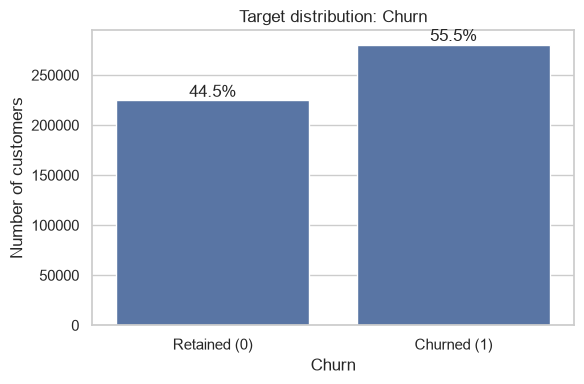

In [8]:
churn_counts = df_raw["Churn"].value_counts()
churn_pct = df_raw["Churn"].value_counts(normalize=True) * 100

churn_summary = pd.DataFrame({"Count": churn_counts, "Percent": churn_pct.round(2)})
print(churn_summary)

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_raw, x="Churn")
ax.set_xticks([0, 1], ["Retained (0)", "Churned (1)"])
ax.set_title("Target distribution: Churn")
ax.set_ylabel("Number of customers")

for bar, pct in zip(ax.patches, churn_pct.sort_index()):
    ax.annotate(f"{pct:.1f}%",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()

**Observation:** 55.5% of customers churned and 44.5% stayed. The classes are fairly
balanced, so plain churn rates (%) are meaningful comparisons, but more than half of
the customers in this data left, which is a serious retention problem.

## 2. Data Cleaning  (rubric #2)

In [9]:
# Work on a copy so df_raw stays untouched.
df = df_raw.copy()

### 2.1 Missing values

In [10]:
# how="all" drops a row only if EVERY column is empty. That is safer than the default
# (how="any"), which would also drop rows with just one missing cell.
rows_before = len(df)
df = df.dropna(how="all")
print(f"Rows before: {rows_before}, after: {len(df)}, dropped: {rows_before - len(df)}")
print(f"Missing values left: {df.isnull().sum().sum()}")

Rows before: 505207, after: 505206, dropped: 1
Missing values left: 0


**Observation:** dropped 1 row. It was completely empty (no ID, no churn label), so it
carries no information and nothing is lost by removing it.
Note: dropna() keeps the original row numbers (index labels), so row 199295 is now
simply missing from the index. We rely on that in 2.4, so we do NOT reset the index.

### 2.2 Column names -> snake_case (e.g. "Support Calls" -> "support_calls")

In [11]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
print(df.columns.tolist())

['customerid', 'age', 'gender', 'tenure', 'usage_frequency', 'support_calls', 'payment_delay', 'subscription_type', 'contract_length', 'total_spend', 'last_interaction', 'churn']


### 2.3 Fix data types

In [12]:
# Now that the empty row is gone, the whole-number columns have no NaN
# and can be converted back to int.
int_cols = ["customerid", "age", "tenure", "usage_frequency", "support_calls",
            "payment_delay", "last_interaction", "churn"]

# Safety check before converting: make sure every value really is a whole number,
# otherwise .astype(int) would silently cut off the decimals.
for col in int_cols:
    assert (df[col] % 1 == 0).all(), f"{col} has decimal values!"

df[int_cols] = df[int_cols].astype(int)
# total_spend really has decimals (e.g. 584.37), so it stays float.
print(df.dtypes)

customerid             int64
age                    int64
gender                   str
tenure                 int64
usage_frequency        int64
support_calls          int64
payment_delay          int64
subscription_type        str
contract_length          str
total_spend          float64
last_interaction       int64
churn                  int64
dtype: object

**Observation:** 8 columns converted from float64 to int64. total_spend stays float64.
The 3 text columns are cleaned and converted to "category" in 2.7.

### 2.4 Duplicate IDs: keep the rows, but make them distinguishable

In [13]:
# split_idx comes from task 1.5 (the row where the ID numbering restarts).
# Rows with an index label before it belong to the first file (A), the rest to B.
df["source"] = np.where(df.index < split_idx, "A", "B")

# A truly unique key per customer: source + ID, e.g. "A-2" and "B-2".
df["customer_key"] = df["source"] + "-" + df["customerid"].astype(str)
print(df["source"].value_counts())
print(f"customer_key unique: {df['customer_key'].is_unique}")

# Why not drop the duplicated IDs (like the reference notebook does)?
# Compare the churn rate of those rows against everyone else.
is_dup_id = df["customerid"].duplicated(keep=False)   # keep=False marks BOTH copies
print(f"\nRows with a duplicated ID: {is_dup_id.sum()} ({is_dup_id.mean() * 100:.1f}%)")
print(f"Churn rate, duplicated-ID rows: {df.loc[is_dup_id, 'churn'].mean() * 100:.1f}%")
print(f"Churn rate, all other rows:     {df.loc[~is_dup_id, 'churn'].mean() * 100:.1f}%")

source
A    440832
B     64374
Name: count, dtype: int64
customer_key unique: True

Rows with a duplicated ID: 125990 (24.9%)
Churn rate, duplicated-ID rows: 72.4%
Churn rate, all other rows:     49.9%


**Observation:** the duplicated IDs are ID collisions between two stacked files, not
repeated customers. Those ~126k rows (25% of the data) churn at about 72%, against about
50% for the rest. Dropping them would remove a large, mostly-churned group and bias every
result, so we keep all rows and use "source" / "customer_key" to tell them apart.

### 2.5 Invalid values / range check

In [14]:
num_cols = ["age", "tenure", "usage_frequency", "support_calls",
            "payment_delay", "total_spend", "last_interaction"]
print(df[num_cols].describe().T[["min", "max", "mean"]])

# Write down what a VALID value looks like, then count anything outside it.
valid_ranges = {
    "age": (18, 100),              # adult customers
    "tenure": (0, None),           # can't be negative
    "usage_frequency": (0, None),
    "support_calls": (0, None),
    "payment_delay": (0, None),
    "total_spend": (0, None),
    "last_interaction": (0, None),
}
for col, (low, high) in valid_ranges.items():
    too_low = (df[col] < low).sum()
    too_high = (df[col] > high).sum() if high is not None else 0
    print(f"{col:17s} invalid: {too_low + too_high}")
print(f"churn values: {sorted(df['churn'].unique())}")

                    min     max        mean
age                18.0    65.0   39.704172
tenure              1.0    60.0   31.350435
usage_frequency     1.0    30.0   15.714825
support_calls       0.0    10.0    3.833317
payment_delay       0.0    30.0   13.496843
total_spend       100.0  1000.0  620.072766
last_interaction    1.0    30.0   14.610581
age               invalid: 0
tenure            invalid: 0
usage_frequency   invalid: 0
support_calls     invalid: 0
payment_delay     invalid: 0
total_spend       invalid: 0
last_interaction  invalid: 0
churn values: [np.int64(0), np.int64(1)]


**Observation:** no invalid values. Age is 18-65, there are no negative counts or spend,
payment_delay is 0-30 days, and churn only contains 0 and 1. Nothing to fix.

### 2.6 Outliers (IQR method)

             column  lower   upper  outliers  pct
0               age   -1.0    79.0         0  0.0
1            tenure  -29.0    91.0         0  0.0
2   usage_frequency  -14.5    45.5         0  0.0
3     support_calls   -6.5    13.5         0  0.0
4     payment_delay  -15.0    41.0         0  0.0
5       total_spend -121.0  1391.0         0  0.0
6  last_interaction  -15.5    44.5         0  0.0


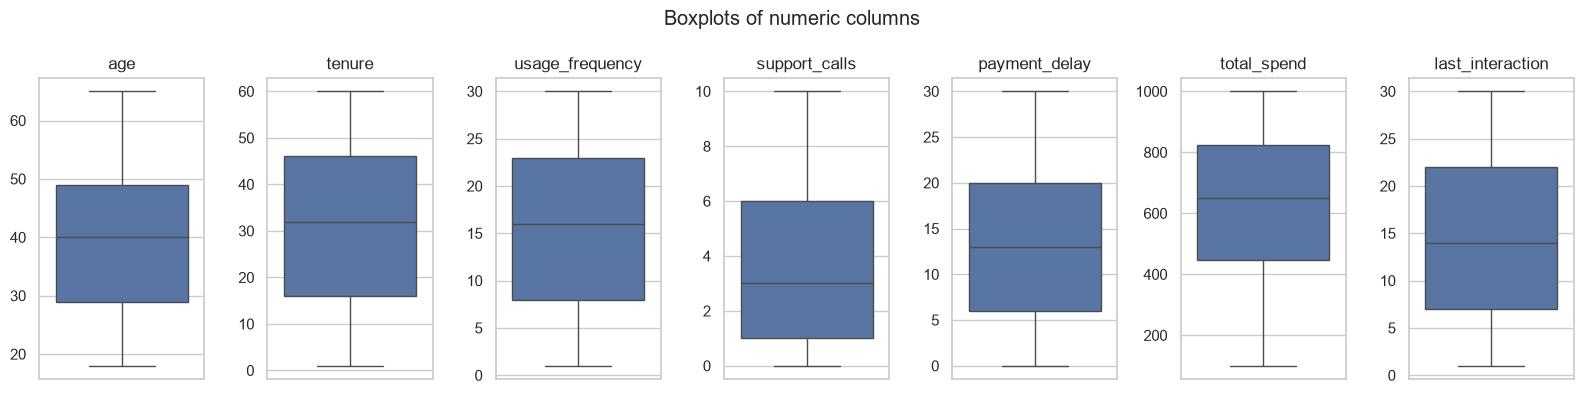

In [15]:
# IQR = Q3 - Q1 (the range of the middle 50%). Values more than 1.5 x IQR
# below Q1 or above Q3 are classic "outliers".
outlier_rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_rows.append({"column": col, "lower": lower, "upper": upper,
                         "outliers": n_out, "pct": round(n_out / len(df) * 100, 2)})
print(pd.DataFrame(outlier_rows))

fig, axes = plt.subplots(1, len(num_cols), figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
plt.suptitle("Boxplots of numeric columns")
plt.tight_layout()
plt.show()

**Observation:** no column has values outside its IQR bounds, and every value is
already within a realistic range (2.5). Nothing is removed. (Even if the IQR method had
flagged values, we would only remove them if they were impossible, not just rare.)

### 2.7 Category cleaning

In [16]:
cat_cols = ["gender", "subscription_type", "contract_length"]
for col in cat_cols:
    print(f"{col}: {df[col].value_counts().to_dict()}")

# Standardise anyway: strip spaces + Title Case, so "  male" and "Male" would merge.
# Running this on already-clean data is harmless, and it protects against future files.
for col in cat_cols:
    df[col] = df[col].str.strip().str.title()

# "category" dtype: stores each label once and uses less memory. We also give
# contract_length and subscription_type a logical ORDER, so charts sort nicely later.
df["gender"] = df["gender"].astype("category")
df["contract_length"] = pd.Categorical(
    df["contract_length"], categories=["Monthly", "Quarterly", "Annual"], ordered=True)
df["subscription_type"] = pd.Categorical(
    df["subscription_type"], categories=["Basic", "Standard", "Premium"], ordered=True)

print(f"\nNaN created by the conversion: {df[cat_cols].isnull().sum().sum()}")  # 0 = no typos
print(f"Clean dataset: {df.shape[0]} rows x {df.shape[1]} columns")
df.info()

gender: {'Male': 280273, 'Female': 224933}
subscription_type: {'Standard': 170630, 'Premium': 170099, 'Basic': 164477}
contract_length: {'Annual': 198608, 'Quarterly': 197364, 'Monthly': 109234}



NaN created by the conversion: 0
Clean dataset: 505206 rows x 14 columns
<class 'pandas.DataFrame'>
Index: 505206 entries, 0 to 505206
Data columns (total 14 columns):
 #   Column             Non-Null Count   Dtype   
---  ------             --------------   -----   
 0   customerid         505206 non-null  int64   
 1   age                505206 non-null  int64   
 2   gender             505206 non-null  category
 3   tenure             505206 non-null  int64   
 4   usage_frequency    505206 non-null  int64   
 5   support_calls      505206 non-null  int64   
 6   payment_delay      505206 non-null  int64   
 7   subscription_type  505206 non-null  category
 8   contract_length    505206 non-null  category
 9   total_spend        505206 non-null  float64 
 10  last_interaction   505206 non-null  int64   
 11  churn              505206 non-null  int64   
 12  source             505206 non-null  str     
 13  customer_key       505206 non-null  str     
dtypes: category(3), float64(1)

**Observation:** the labels are already clean, with no typos, extra spaces or mixed case.
Gender: Male/Female; Subscription: Basic/Standard/Premium; Contract: Monthly/Quarterly/
Annual. They are converted to the category dtype with a logical order.
Final clean dataset: 505,206 rows x 14 columns (12 original + source + customer_key).

## 3. Descriptive Statistics  (rubric #3)

### 3.1 Numerical summary

In [17]:
# num_cols (from 2.5) = the 7 numeric features. customerid and churn are left out:
# the mean of an ID is meaningless, and churn is the target (covered in 1.6).
summary = df[num_cols].describe().T
summary["median"] = df[num_cols].median()
summary["skew"] = df[num_cols].skew()        # 0 = symmetric, >0 = long right tail, <0 = long left tail
summary["kurtosis"] = df[num_cols].kurt()    # <0 = flatter than a bell curve, >0 = more peaked
print(summary.round(2))
# How to read skew: |skew| < 0.5 is roughly symmetric, 0.5-1 moderately skewed, > 1 highly skewed.

                     count    mean     std    min    25%    50%    75%  \
age               505206.0   39.70   12.67   18.0   29.0   40.0   49.0   
tenure            505206.0   31.35   17.24    1.0   16.0   32.0   46.0   
usage_frequency   505206.0   15.71    8.62    1.0    8.0   16.0   23.0   
support_calls     505206.0    3.83    3.13    0.0    1.0    3.0    6.0   
payment_delay     505206.0   13.50    8.45    0.0    6.0   13.0   20.0   
total_spend       505206.0  620.07  245.32  100.0  446.0  648.9  824.0   
last_interaction  505206.0   14.61    8.61    1.0    7.0   14.0   22.0   

                     max  median  skew  kurtosis  
age                 65.0    40.0  0.14     -0.92  
tenure              60.0    32.0 -0.07     -1.19  
usage_frequency     30.0    16.0 -0.03     -1.18  
support_calls       10.0     3.0  0.54     -0.94  
payment_delay       30.0    13.0  0.20     -0.99  
total_spend       1000.0   648.9 -0.39     -0.87  
last_interaction    30.0    14.0  0.15     -1.16  

**Observation:**
- Mean ≈ median for every column, and every |skew| is ≤ 0.54, so no column is heavily skewed.
- support_calls is the most right-skewed (0.54): most customers make few calls (median 3),
  and a smaller group makes many (up to 10).
- total_spend is slightly left-skewed (-0.39): median 649 > mean 620, so more customers
  are at the high end of spend.
- Every kurtosis is about -0.9 to -1.2: the distributions are FLAT (close to uniform),
  not bell-shaped. That is typical of synthetic/generated data. Keep it in mind when
  interpreting results.

### 3.2 Numerical distributions

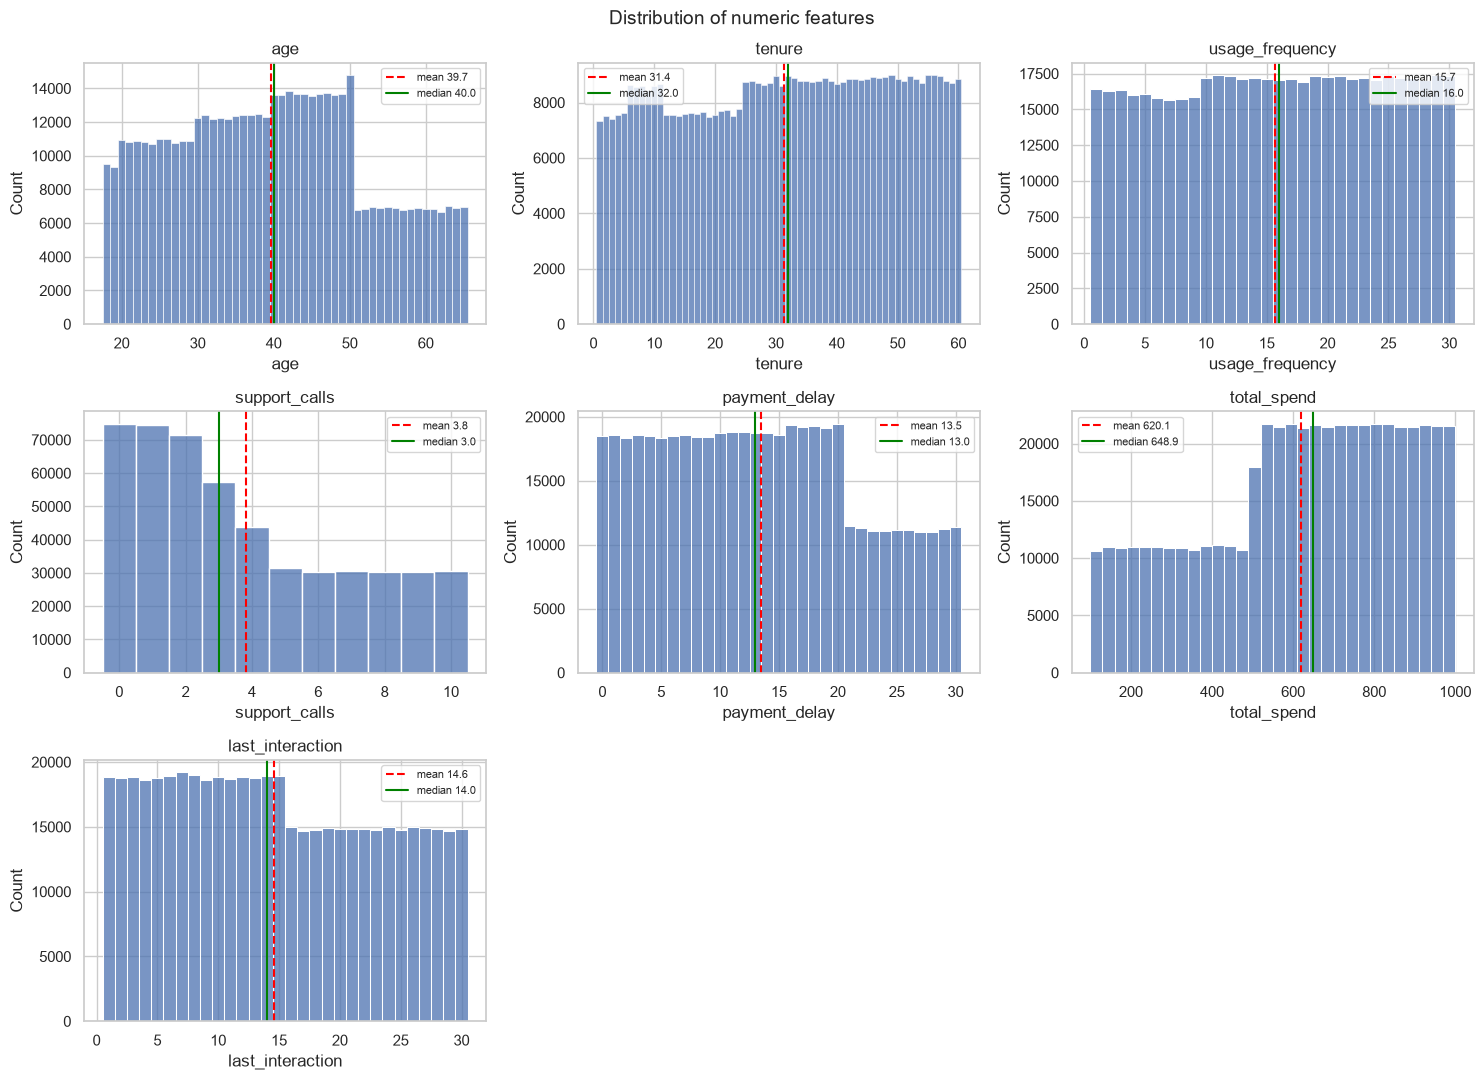

In [18]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    # Whole-number columns: discrete=True gives ONE bar per value (age 18, 19, 20 ...).
    # With bins=30 on whole numbers, some bins catch 2 values and some catch 1,
    # which draws a fake zig-zag pattern. total_spend has decimals, so it uses normal bins.
    if col == "total_spend":
        sns.histplot(df[col], bins=30, ax=ax)
    else:
        sns.histplot(df[col], discrete=True, ax=ax)
    ax.axvline(df[col].mean(), color="red", linestyle="--", label=f"mean {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color="green", linestyle="-", label=f"median {df[col].median():.1f}")
    ax.set_title(col)
    ax.legend(fontsize=8)

for ax in axes[len(num_cols):]:
    ax.set_visible(False)

plt.suptitle("Distribution of numeric features", fontsize=14)
plt.tight_layout()
plt.show()

**Observation:**
- tenure, usage_frequency and last_interaction are close to UNIFORM: every value is
  about equally common.
- support_calls: 0-2 calls are the most common (~15% each), dropping to ~6% each from
  5 calls upwards.
- The distributions have sharp "steps" (sudden level changes) instead of smooth curves:
    - age: the count halves after age 50
    - support_calls: drops after 4 calls, then stays flat from 5 to 10
    - payment_delay: drops by ~40% after 20 days
    - total_spend: doubles above ~500 (fewer low spenders)
    - last_interaction: drops after 14 days

  These thresholds are worth checking against churn in section 4. A step like this
  often marks where customer behaviour changes.

### 3.3 Categorical distributions

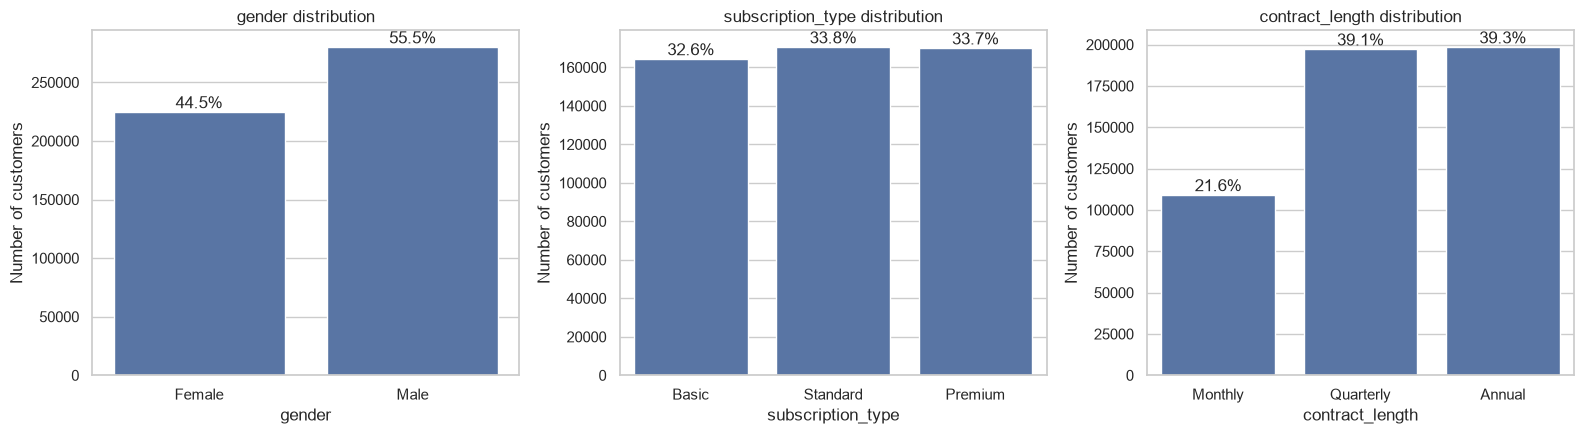


gender:
gender
Female    44.5
Male      55.5
Name: proportion, dtype: float64

subscription_type:
subscription_type
Basic       32.6
Standard    33.8
Premium     33.7
Name: proportion, dtype: float64

contract_length:
contract_length
Monthly      21.6
Quarterly    39.1
Annual       39.3
Name: proportion, dtype: float64


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, col in zip(axes, cat_cols):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f"{col} distribution")
    ax.set_ylabel("Number of customers")
    for bar in ax.patches:
        pct = bar.get_height() / len(df) * 100
        ax.annotate(f"{pct:.1f}%",
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha="center", va="bottom")

plt.tight_layout()
plt.show()

# The same numbers as a table (easier to quote in the report).
for col in cat_cols:
    print(f"\n{col}:")
    print((df[col].value_counts(normalize=True, sort=False) * 100).round(1))

**Observation:**
- gender: Male 55.5%, Female 44.5%, so slightly more men.
- subscription_type: Basic 32.6%, Standard 33.8%, Premium 33.7%, almost an even split.
- contract_length: Annual 39.3%, Quarterly 39.1%, Monthly only 21.6%. Most customers
  are on longer contracts. Monthly is the smallest group; section 4 checks whether it
  churns differently.

## 4. Relationship Analysis  (rubric #4)

Section 3 described each column ON ITS OWN (univariate analysis).
Section 4 compares each column WITH churn (bivariate analysis): does churn go up or down
as the column changes? The main tool is the CHURN RATE per group:

    churn rate of a group = churned customers in the group / all customers in the group

We compare every group against the overall churn rate (55.5%). A group far above it
is a risk group; a group far below it is a loyal group.

In [20]:
# Reusable helpers for every churn-rate table and chart below.

overall_churn = df["churn"].mean() * 100


def churn_rate_table(data, col):
    """Return Total_Users, Churn_Users and Churn_Rate (%) for each value of col."""
    # observed=True: for category columns, only show categories that actually occur.
    table = data.groupby(col, observed=True).agg(
        Total_Users=("churn", "count"),   # how many customers in the group
        Churn_Users=("churn", "sum"),     # churn is 0/1, so the sum = number who churned
    )
    table["Churn_Rate"] = (table["Churn_Users"] / table["Total_Users"] * 100).round(1)
    return table


def plot_churn_rate(data, col, title, ax=None, rotate=0):
    """Bar chart of churn rate by col, with % labels and a line for the overall rate."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4.5))
    table = churn_rate_table(data, col).reset_index()
    sns.barplot(data=table, x=col, y="Churn_Rate", ax=ax, color="steelblue")
    # Dashed line = overall churn rate. Bars above it are higher-risk groups.
    ax.axhline(overall_churn, color="red", linestyle="--",
               label=f"overall {overall_churn:.1f}%")
    for bar in ax.patches:
        ax.annotate(f"{bar.get_height():.1f}%",
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha="center", va="bottom", fontsize=9)
    ax.set_ylim(0, 105)
    ax.set_ylabel("Churn rate (%)")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=rotate)
    ax.legend(loc="lower right", fontsize=8)
    return ax

### 4.1 Churn by contract_length *(required by the brief)*

                 Total_Users  Churn_Users  Churn_Rate
contract_length                                      
Monthly               109234        98525        90.2
Quarterly             197364        90426        45.8
Annual                198608        91541        46.1


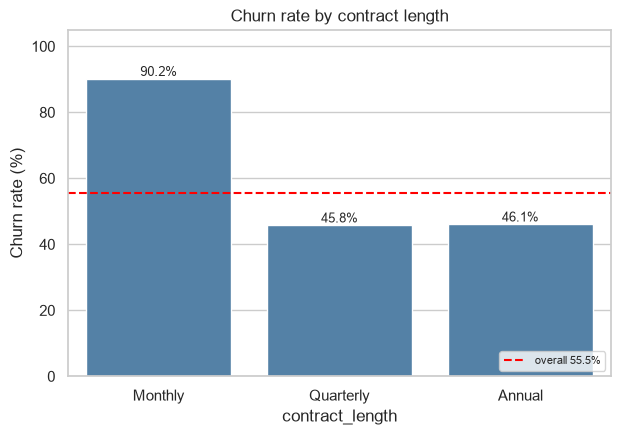

In [21]:
print(churn_rate_table(df, "contract_length"))
plot_churn_rate(df, "contract_length", "Churn rate by contract length")
plt.show()

**Observation:** Monthly customers churn at 90.2%, about double Quarterly (45.8%) and
Annual (46.1%). Quarterly and Annual are almost identical, so the big difference is
simply "monthly vs. any longer contract". Monthly is 21.6% of customers (3.3).

### 4.2 Churn by subscription_type *(required by the brief)*

                   Total_Users  Churn_Users  Churn_Rate
subscription_type                                      
Basic                   164477        93566        56.9
Standard                170630        93793        55.0
Premium                 170099        93133        54.8


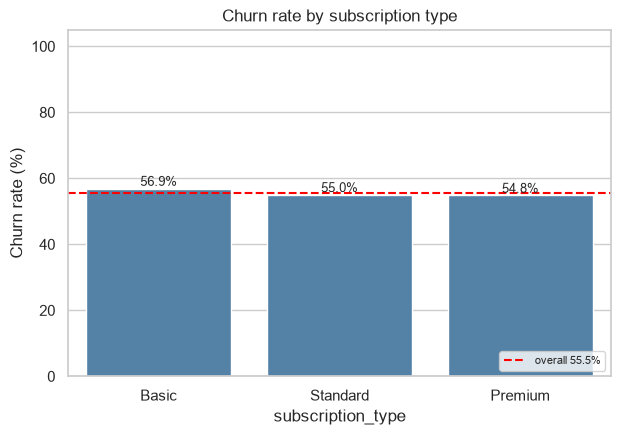

In [22]:
print(churn_rate_table(df, "subscription_type"))
plot_churn_rate(df, "subscription_type", "Churn rate by subscription type")
plt.show()

**Observation:** Basic 56.9%, Standard 55.0%, Premium 54.8%. The difference is only ~2
percentage points, so subscription type has almost NO effect on churn. Upgrading
customers to Premium on its own would not keep them.

### 4.3 Churn by payment_delay bucket *(required by the brief)*

             Total_Users  Churn_Users  Churn_Rate
delay_group                                      
0-5               110817        48077        43.4
6-10               92612        40278        43.5
11-15              93559        40673        43.5
16-20              96509        46233        47.9
21-25              55966        52749        94.3
26-30              55743        52482        94.1


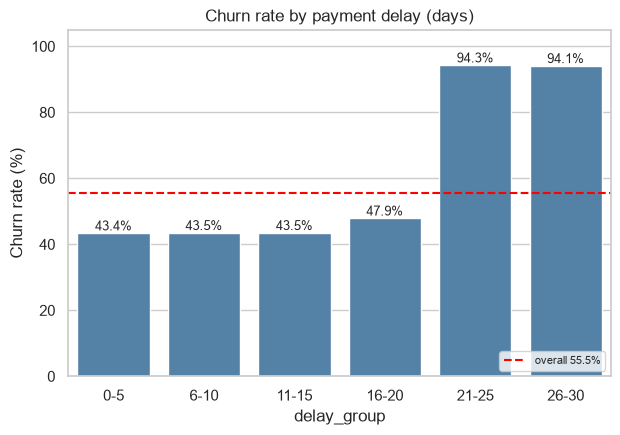

In [23]:
# Bins start at -1 because pd.cut excludes the left edge (so 0 days is kept).
df["delay_group"] = pd.cut(df["payment_delay"],
                           bins=[-1, 5, 10, 15, 20, 25, 30],
                           labels=["0-5", "6-10", "11-15", "16-20", "21-25", "26-30"])
print(churn_rate_table(df, "delay_group"))
plot_churn_rate(df, "delay_group", "Churn rate by payment delay (days)")
plt.show()

**Observation:** a clear THRESHOLD at 20 days. Up to 15 days churn is flat at ~43.5%,
rising a little to 47.9% at 16-20 days, then jumping to ~94% from 21 days onwards.
This matches the "step" seen in the payment_delay histogram in 3.2.

### 4.4 Churn by gender

        Total_Users  Churn_Users  Churn_Rate
gender                                      
Female       224933       145969        64.9
Male         280273       134523        48.0


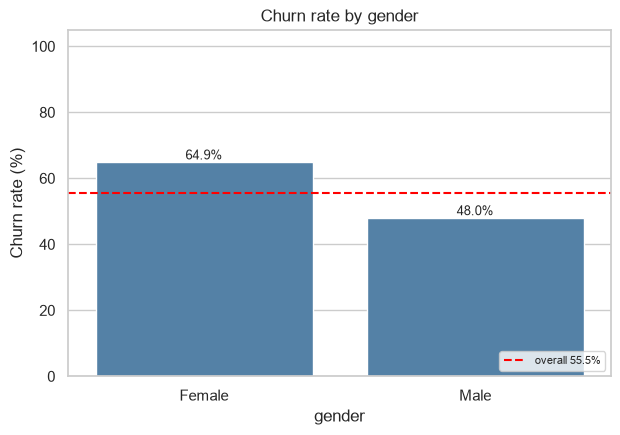

In [24]:
print(churn_rate_table(df, "gender"))
plot_churn_rate(df, "gender", "Churn rate by gender")
plt.show()

**Observation:** women churn at 64.9% against 48.0% for men, a 17-point gap, even though
there are fewer women (44.5%). Gender is a meaningful churn factor here.

### 4.5 Churn by support_calls (0-10, one bar each)

               Total_Users  Churn_Users  Churn_Rate
support_calls                                      
0                    74842        22363        29.9
1                    74405        22223        29.9
2                    71383        22118        31.0
3                    57452        23131        40.3
4                    43898        24307        55.4
5                    31575        27626        87.5
6                    30193        27578        91.3
7                    30469        27947        91.7
8                    30208        27612        91.4
9                    30294        27689        91.4
10                   30487        27898        91.5


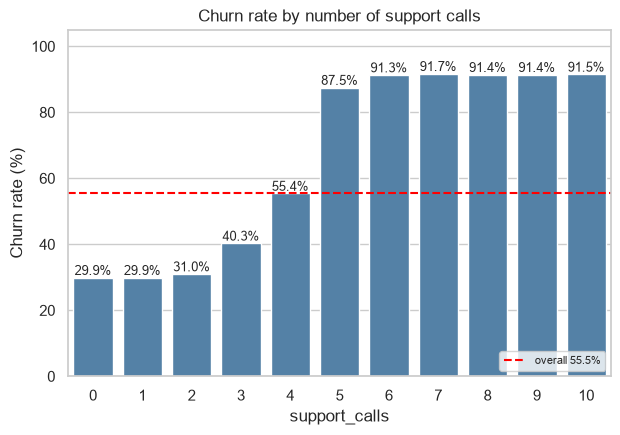

In [25]:
print(churn_rate_table(df, "support_calls"))
plot_churn_rate(df, "support_calls", "Churn rate by number of support calls")
plt.show()

**Observation:** churn rises steadily with support calls: ~30% at 0-2 calls, 40.3% at 3,
55.4% at 4, then jumps to 87.5% at 5 calls and ~91% from 6 calls up.
-> 5 calls is the tipping point. Customers who keep calling probably have unresolved
   problems. The 3rd-4th call is the moment to step in.

### 4.6 Churn by age group / tenure group / usage_frequency / last_interaction

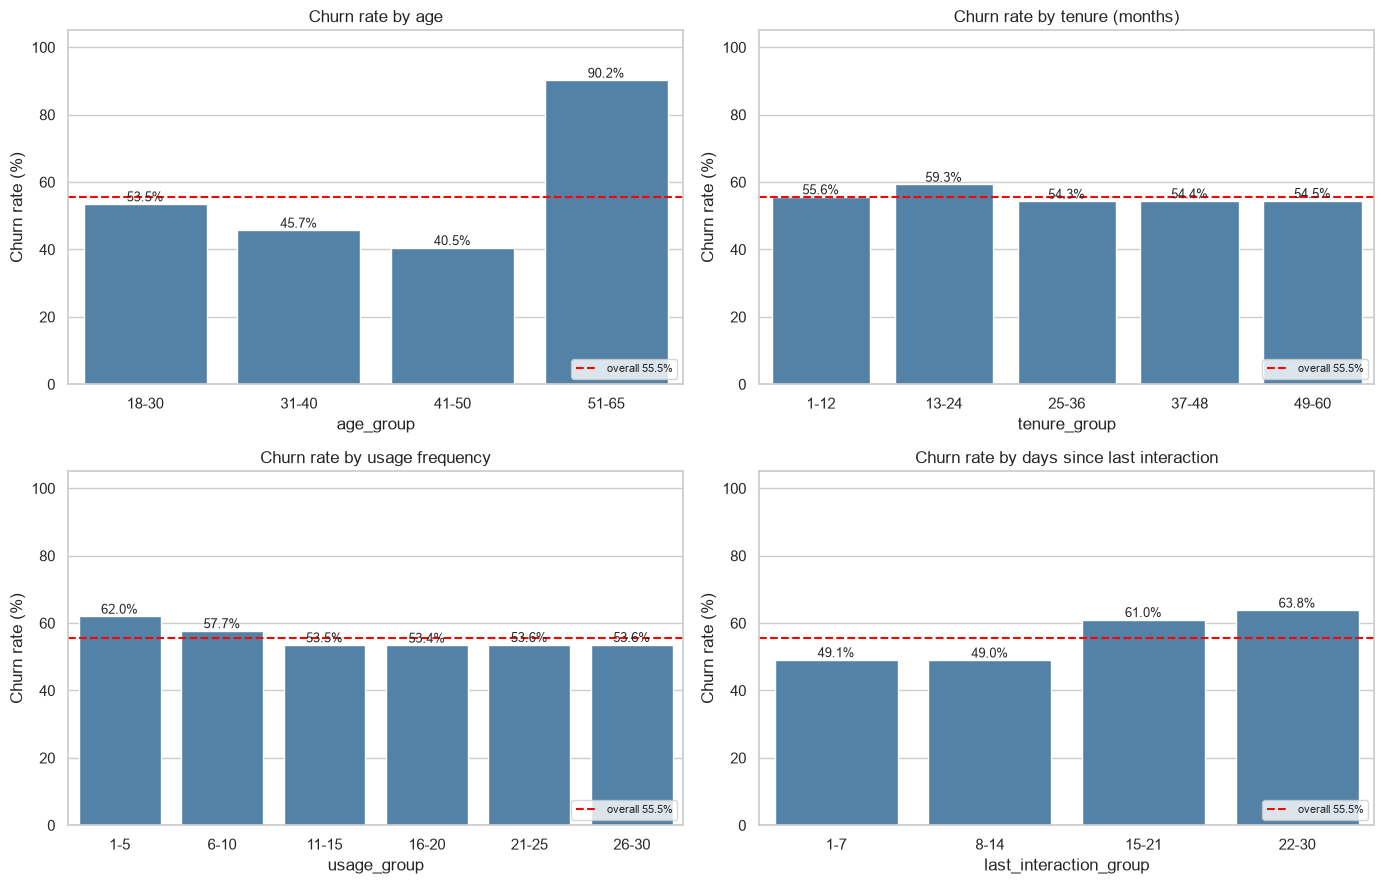


           Total_Users  Churn_Users  Churn_Rate
age_group                                      
18-30           139804        74785        53.5
31-40           124592        56905        45.7
41-50           137798        55844        40.5
51-65           103012        92958        90.2

              Total_Users  Churn_Users  Churn_Rate
tenure_group                                      
1-12                96489        53616        55.6
13-24               91254        54143        59.3
25-36              105237        57173        54.3
37-48              105900        57637        54.4
49-60              106326        57923        54.5

             Total_Users  Churn_Users  Churn_Rate
usage_group                                      
1-5                81038        50212        62.0
6-10               80198        46263        57.7
11-15              86148        46047        53.5
16-20              85660        45745        53.4
21-25              86018        46076        53.6
26

In [26]:
df["age_group"] = pd.cut(df["age"], bins=[17, 30, 40, 50, 65],
                         labels=["18-30", "31-40", "41-50", "51-65"])
df["tenure_group"] = pd.cut(df["tenure"], bins=[0, 12, 24, 36, 48, 60],
                            labels=["1-12", "13-24", "25-36", "37-48", "49-60"])
df["usage_group"] = pd.cut(df["usage_frequency"], bins=[0, 5, 10, 15, 20, 25, 30],
                           labels=["1-5", "6-10", "11-15", "16-20", "21-25", "26-30"])
df["last_interaction_group"] = pd.cut(df["last_interaction"], bins=[0, 7, 14, 21, 30],
                                      labels=["1-7", "8-14", "15-21", "22-30"])

group_cols = {
    "age_group": "Churn rate by age",
    "tenure_group": "Churn rate by tenure (months)",
    "usage_group": "Churn rate by usage frequency",
    "last_interaction_group": "Churn rate by days since last interaction",
}
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (col, title) in zip(axes.flatten(), group_cols.items()):
    plot_churn_rate(df, col, title, ax=ax)
plt.tight_layout()
plt.show()

for col in group_cols:
    print(f"\n{churn_rate_table(df, col)}")

**Observation:**
- Age: churn FALLS from 53.5% (18-30) to 40.5% (41-50), then JUMPS to 90.2% for 51-65.
  The 51+ group is the second clear threshold (it matches the age "step" in 3.2).
- Tenure: flat (54-59%) in every group, so how long someone has been a customer barely matters.
- Usage frequency: low users (1-5 times) churn a bit more (62.0%) than the rest (~53.5%).
- Last interaction: customers inactive for 15+ days churn at 61-64% against 49% for those
  active in the last 2 weeks. Inactivity is a moderate warning sign.

### 4.7 Total spend: churned vs retained

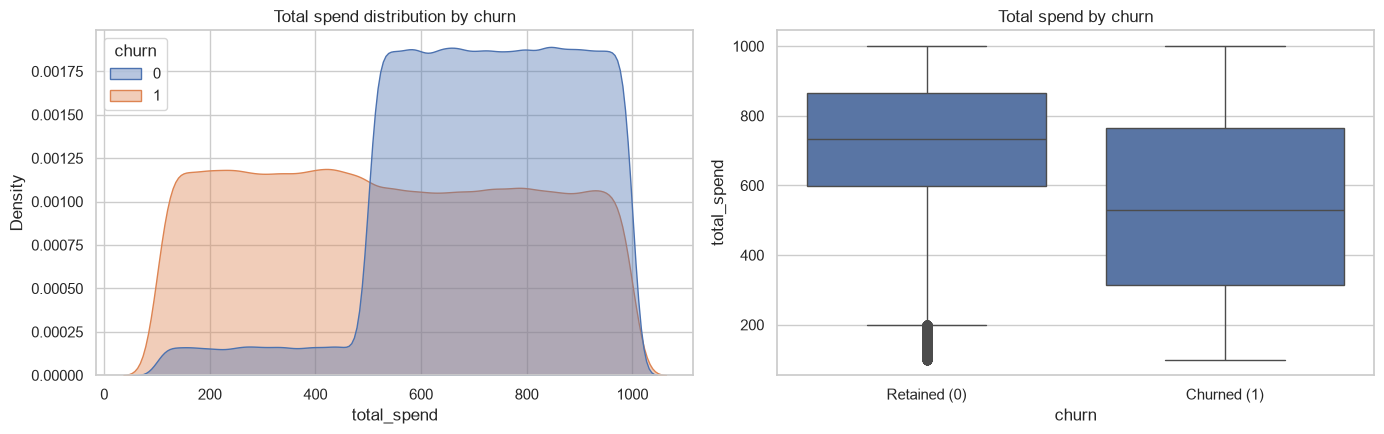

        mean  median    std
churn                      
0      721.4   733.0  180.1
1      538.9   529.4  260.0
             Total_Users  Churn_Users  Churn_Rate
spend_group                                      
100-250            54843        49540        90.3
251-500            91153        82129        90.1
501-750           179653        74505        41.5
751-1000          179557        74318        41.4


In [27]:
# total_spend is continuous, so we compare the two DISTRIBUTIONS instead of a single bar.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# KDE = smoothed histogram. common_norm=False scales each group to its own size,
# so the two curves can be compared even though the groups have different sizes.
sns.kdeplot(data=df, x="total_spend", hue="churn", fill=True,
            common_norm=False, alpha=0.4, ax=axes[0])
axes[0].set_title("Total spend distribution by churn")

sns.boxplot(data=df, x="churn", y="total_spend", ax=axes[1])
axes[1].set_xticks([0, 1], ["Retained (0)", "Churned (1)"])
axes[1].set_title("Total spend by churn")
plt.tight_layout()
plt.show()

print(df.groupby("churn")["total_spend"].agg(["mean", "median", "std"]).round(1))

df["spend_group"] = pd.cut(df["total_spend"], bins=[0, 250, 500, 750, 1000],
                           labels=["100-250", "251-500", "501-750", "751-1000"])
print(churn_rate_table(df, "spend_group"))

**Observation:** churned customers spend less (median 529 vs 733). The spend-group table
shows a hard THRESHOLD at 500: customers who spent up to 500 churn at ~90%, those
above 500 at ~41.5%. Within each side the rate is flat, so it is the 500 line that
matters, not "every extra dollar".

### 4.8 Correlation matrix

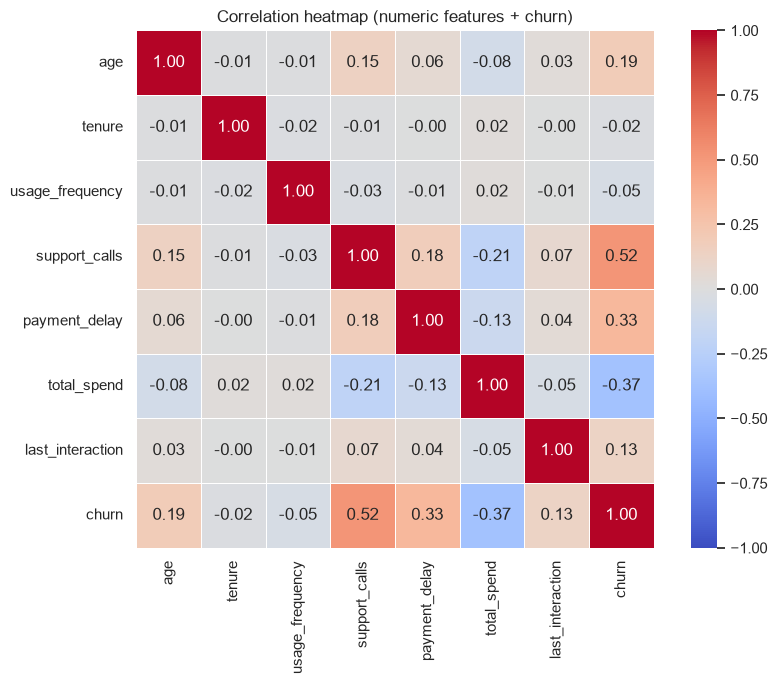

Correlation with churn (strongest first):
support_calls       0.52
total_spend        -0.37
payment_delay       0.33
age                 0.19
last_interaction    0.13
usage_frequency    -0.05
tenure             -0.02
Name: churn, dtype: float64


In [28]:
# Pearson correlation: -1 (perfect opposite) ... 0 (no linear relation) ... +1 (perfect together).
# customerid is left out: an ID number has no meaning, so any correlation with it is noise.
corr = df[num_cols + ["churn"]].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, square=True)
plt.title("Correlation heatmap (numeric features + churn)")
plt.tight_layout()
plt.show()

churn_corr = corr["churn"].drop("churn").sort_values(key=abs, ascending=False)
print("Correlation with churn (strongest first):")
print(churn_corr.round(2))

**Observation:**
- Strongest links with churn: support_calls (+0.52), total_spend (-0.37),
  payment_delay (+0.33), age (+0.19). Tenure and usage_frequency are near 0.
- + means "higher value -> more churn"; - means "higher value -> less churn".
- Feature-to-feature correlations are all weak (|r| <= 0.21), so the features are not
  duplicates of each other. Each one adds its own information.
- Correlation only measures STRAIGHT-LINE relationships. Our churn patterns are
  thresholds (a sudden jump at 5 calls, 20 days, age 50, spend 500), so the churn-rate
  charts above describe them better than a single correlation number.

### 4.9 Source A vs Source B

              rule source  churn_in_group  churn_outside
  Monthly contract      A           100.0           46.1
  Monthly contract      B            51.6           45.1
Support calls >= 5      A            99.1           36.3
Support calls >= 5      B            60.9           25.5
Payment delay > 20      A           100.0           46.5
Payment delay > 20      B            76.6           25.3
          Age > 50      A           100.0           46.9
          Age > 50      B            52.9           44.6
Total spend <= 500      A           100.0           41.2
Total spend <= 500      B            52.2           43.2
            Female      A            66.7           49.1
            Female      B            55.0           38.6


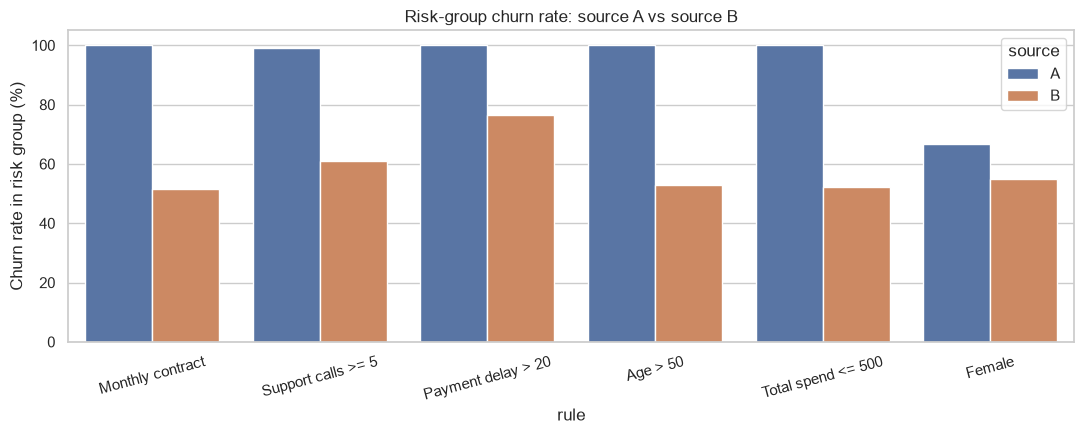

In [29]:
# Are the patterns the same in both stacked files? We test each risk rule
# ("is this customer in the risk group?") separately in A and B.
risk_rules = {
    "Monthly contract":   df["contract_length"] == "Monthly",
    "Support calls >= 5": df["support_calls"] >= 5,
    "Payment delay > 20": df["payment_delay"] > 20,
    "Age > 50":           df["age"] > 50,
    "Total spend <= 500": df["total_spend"] <= 500,
    "Female":             df["gender"] == "Female",
}

rows = []
for rule_name, in_group in risk_rules.items():
    for src in ["A", "B"]:
        in_src = df["source"] == src
        rows.append({
            "rule": rule_name,
            "source": src,
            "churn_in_group": df.loc[in_src & in_group, "churn"].mean() * 100,
            "churn_outside": df.loc[in_src & ~in_group, "churn"].mean() * 100,
        })
source_compare = pd.DataFrame(rows).round(1)
print(source_compare.to_string(index=False))

plt.figure(figsize=(11, 4.5))
sns.barplot(data=source_compare, x="rule", y="churn_in_group", hue="source")
plt.ylabel("Churn rate in risk group (%)")
plt.title("Risk-group churn rate: source A vs source B")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Observation:**
- In source A, Monthly / payment delay > 20 / age > 50 / spend <= 500 churn at exactly
  100%, and support calls >= 5 at 99.1%. Perfect splits like this are almost never seen in
  real customers, which again suggests generated data.
- In source B the same groups churn much less: payment delay > 20 -> 76.6% (vs 25.3%
  outside), support calls >= 5 -> 60.9% (vs 25.5%), Female 55.0% (vs 38.6%). Monthly,
  age > 50 and low spend only add a few points there (about +6 to +9).
-> Payment delay, support calls and gender are the ROBUST signals: strong in both sources.
   The contract, age and spend thresholds are strong in A but weak in B, so present them
   with that caveat.

### 4.10 Putting the signals together

In [30]:
# How many customers hit AT LEAST ONE of the main risk rules, and how do they churn?
any_risk = (risk_rules["Monthly contract"] | risk_rules["Support calls >= 5"]
            | risk_rules["Payment delay > 20"] | risk_rules["Age > 50"]
            | risk_rules["Total spend <= 500"])
print(f"Customers with at least one risk flag: {any_risk.mean() * 100:.1f}%")
print(f"  churn rate WITH a flag:    {df.loc[any_risk, 'churn'].mean() * 100:.1f}%")
print(f"  churn rate WITHOUT a flag: {df.loc[~any_risk, 'churn'].mean() * 100:.1f}%")

Customers with at least one risk flag: 59.9%
  churn rate WITH a flag:    89.5%
  churn rate WITHOUT a flag: 4.7%


**Observation:** 59.9% of customers have at least one risk flag, and they churn at 89.5%.
Customers with NO flag churn at only 4.7%. These five simple rules separate churners
from loyal customers very well, which makes them a practical early-warning list for the
retention team (section 5).

## 5. Business Insights & Recommendations  (rubric #5)

Section 4 found WHAT is related to churn. This section answers the business question
from the brief: **who leaves, and what can the company do about it?**

The steps:
1. Rank the churn drivers in one chart (5.1)
2. Write each insight with its evidence (5.2)
3. Turn each insight into an action: who, what, when (5.3)
4. State the limits of the analysis honestly (5.4), and what comes next (5.5)

### 5.1 Key churn drivers at a glance

            driver  customers_pct  churn_in_group  churn_outside  uplift_pts
Support calls >= 5           36.3            90.8           35.5        55.3
Payment delay > 20           22.1            94.2           44.5        49.7
Total spend <= 500           28.9            90.2           41.4        48.8
  Monthly contract           21.6            90.2           46.0        44.2
          Age > 50           20.4            90.2           46.6        43.6
            Female           44.5            64.9           48.0        16.9


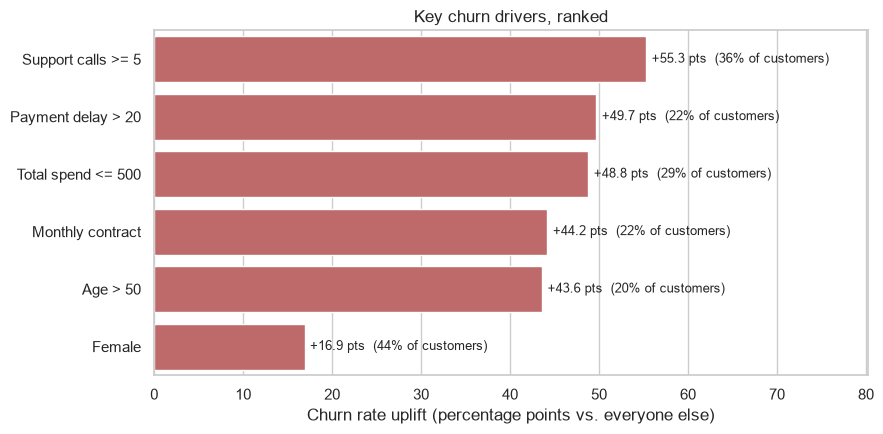

In [31]:
# For each risk rule from 4.9 we measure the "uplift":
#     uplift = churn rate INSIDE the group - churn rate OUTSIDE the group
# A big uplift = belonging to that group makes churn much more likely.
# We also note how many customers each rule covers, because a big uplift on a tiny group
# matters less than a moderate uplift on a big one.
driver_rows = []
for rule_name, in_group in risk_rules.items():
    churn_in = df.loc[in_group, "churn"].mean() * 100
    churn_out = df.loc[~in_group, "churn"].mean() * 100
    driver_rows.append({
        "driver": rule_name,
        "customers_pct": round(in_group.mean() * 100, 1),
        "churn_in_group": round(churn_in, 1),
        "churn_outside": round(churn_out, 1),
        "uplift_pts": round(churn_in - churn_out, 1),
    })
drivers = pd.DataFrame(driver_rows).sort_values("uplift_pts", ascending=False)
print(drivers.to_string(index=False))

plt.figure(figsize=(9, 4.5))
ax = sns.barplot(data=drivers, y="driver", x="uplift_pts", color="indianred")
for bar, share in zip(ax.patches, drivers["customers_pct"]):
    ax.annotate(f"+{bar.get_width():.1f} pts  ({share:.0f}% of customers)",
                (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                va="center", ha="left", fontsize=9, xytext=(4, 0), textcoords="offset points")
ax.set_xlim(0, drivers["uplift_pts"].max() * 1.45)   # leave room for the labels
ax.set_xlabel("Churn rate uplift (percentage points vs. everyone else)")
ax.set_ylabel("")
ax.set_title("Key churn drivers, ranked")
plt.tight_layout()
plt.show()

**Observation:** support calls >= 5 has the biggest uplift (+55.3 pts) and covers the most
customers (36.3%). Payment delay > 20, spend <= 500, monthly contract and age > 50 each
raise churn by about 44-50 points. Gender is a smaller (+17 pts) but
still real driver. Each driver covers roughly 20-45% of customers, so none of them is a niche.

### 5.2 Key insights

Overall, **55.5%** of customers churned. The profile of a churned customer is:
*calls support often, pays late, is on a monthly contract, spends little, and is over 50.*

| # | Insight | Evidence | Holds in both sources? |
|---|---|---|---|
| 1 | **Support calls are the strongest warning sign.** Churn climbs with every call and jumps at 5 calls. | 0-2 calls: ~30% → 4 calls: 55.4% → 5+ calls: ~90%. Strongest correlation (+0.52). | ✅ Yes (B: 60.9% vs 25.5%) |
| 2 | **Late payment past 20 days almost guarantees churn.** | ≤15 days: ~43.5%, 16-20: 47.9%, 21+ days: ~94%. | ✅ Yes, strongest in B (76.6% vs 25.3%) |
| 3 | **Monthly contracts churn about twice as often.** | Monthly 90.2% vs Quarterly 45.8% / Annual 46.1%. | ⚠️ Much weaker in B (51.6% vs 45.1%) |
| 4 | **Low spenders leave; spending above 500 marks loyalty.** | Spend ≤500: ~90% vs >500: ~41.5%. Median spend: churned 529 vs retained 733. | ⚠️ Weaker in B (52.2% vs 43.2%) |
| 5 | **Customers over 50 are a high-risk group.** | Age 51-65: 90.2% vs 40-54% for younger groups. | ⚠️ Weaker in B (52.9% vs 44.6%) |
| 6 | **Women churn more than men.** | Female 64.9% vs Male 48.0%. | ✅ Yes (B: 55.0% vs 38.6%) |
| 7 | **Inactivity is an early signal.** | No interaction in 15+ days: 61-64% vs ~49% within 14 days. | ⚠️ Not in B |
| 8 | **What does NOT matter:** subscription type and tenure. | Basic/Standard/Premium: 54.8-56.9%. Tenure groups: 54-59%. | ✅ |

**Combined:** 59.9% of customers match at least one of the 5 main risk rules, and they churn at
**89.5%**. Customers matching none churn at only **4.7%** (4.10).

### 5.3 Recommendations

The brief says the company wants to use **promotions** to reduce churn. Each action
below targets one insight, ordered by priority: the drivers that hold in both sources first.

**1. Fix the support experience before customers give up (Insight 1)**
- *Who:* customers on their **3rd-4th support call** (~20% of customers, churn already 40-55%).
- *What:* escalate them to a senior agent or a dedicated case owner; follow up after the issue
  is closed; offer a goodwill credit or voucher if the problem took more than one call to fix.
- *Why then:* after the 5th call churn is ~90%, which is too late. The 3rd-4th call is the last good moment.
- *Track:* churn rate of customers with 3+ calls; repeat-call rate.

**2. Act on late payments before day 20 (Insight 2)**
- *Who:* customers whose payment is **10-20 days late** (the window before the cliff).
- *What:* automatic reminders at day 5 / 10 / 15; offer instalments, a short grace period, or a
  small discount for switching to auto-pay. Make a personal contact before day 20.
- *Track:* share of late payers who pay before day 21; their churn rate.

**3. Move monthly customers to longer contracts (Insight 3)**
- *Who:* Monthly customers (21.6% of customers, 90.2% churn).
- *What:* a discount or bonus month for upgrading to a Quarterly plan. Quarterly retains as well as
  Annual (45.8% vs 46.1%), so the smaller commitment is enough and easier to sell.
- *Track:* monthly → quarterly conversion rate; churn of converted customers.

**4. Reward customers for crossing the 500 spend mark (Insight 4)**
- *Who:* customers who have spent **below 500** (~29% of customers).
- *What:* loyalty points or a "spend X more, get Y" offer that nudges them past 500; personalised
  product recommendations to raise engagement.

**5. A tailored retention programme for customers over 50 (Insight 5)**
- *What:* simpler onboarding and support (e.g. a phone line with no queue), and targeted offers.
  **First** run a short survey to learn *why* they leave, because the data shows that they leave, not why.

**6. Investigate the gender gap (Insight 6)**
- Women churn 17 points more, in both sources. Before designing promotions, use surveys or
  exit interviews to find the cause (product range? pricing? service?).

**7. Re-engage inactive customers at day 14 (Insight 7)**
- An automatic "we miss you" message or offer when a customer hasn't interacted for 14 days.

**8. Don't spend promotion budget on plan upgrades alone (Insight 8)**
- Basic, Standard and Premium churn at the same rate, so pushing customers to Premium won't keep them.

**Overall:** build an **early-warning list** from the 5 risk rules (4.10) and review it weekly. It
flags the group where ~90% of churn happens and leaves out the group that almost never churns (4.7%),
so retention budget goes where it matters.

### 5.4 Limitations

- **Two stacked sources.** The file combines two datasets (A: 440,832 rows, B: 64,374) whose
  customer IDs overlap. We kept both and labelled them (`source`). Some patterns hold only in A.
- **Likely synthetic data.** Source A has perfect 100% churn groups and almost uniform
  distributions, which real customers rarely show. Real-world effects are probably smaller,
  closer to what source B shows.
- **Correlation is not causation.** For example, many support calls may be a *symptom* of a bad
  experience rather than the cause of churn. Recommendations should be tested (e.g. A/B tests) before rolling out widely.
- **No time dimension.** We can't see *when* customers churned or how behaviour changed before
  churning, so cohort analysis isn't possible with this data.
- **No cost/revenue data.** We can't yet estimate the money each action would save.

### 5.5 Next steps

- **Mini project 2:** build a supervised churn-prediction model (e.g. logistic regression, decision
  tree) using the drivers found here as features. Validate it on source B separately, because source A's
  perfect splits could make a model look unrealistically accurate.
- Add customer feedback (surveys, exit reasons) to explain *why* the high-risk groups leave.